In [ ]:
from pca_utils import *

# Import data

In [2]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/WTaggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS3/MGS3aggregated_data.csv"

In [3]:
df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)

In [4]:
df1["sample"] = "WT"
df2["sample"] = "MGS3"

combined_df = pd.concat(
    [df1, df2],
    ignore_index=True
)

In [5]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 59


In [6]:
combined_df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample
0,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,452,6.838496,2.525441,0.891543,0.923505,4.900340,15.711590,18.807522,13.654867,WT
1,C2_MP_U2OS_fixed_WT_001.nd2_(series_06)_ROI_02...,373,5.316354,2.327790,0.901233,0.926065,3.888791,25.784152,29.471850,23.136729,WT
2,C2_MP_U2OS_fixed_WT_001.nd2_(series_08)_ROI_02...,360,5.705556,2.303457,0.925275,0.934900,3.649699,29.218538,33.625000,26.161111,WT
3,C2_MP_U2OS_fixed_WT_001.nd2_(series_10)_ROI_02...,268,7.865672,2.516320,0.893500,0.939220,4.567975,26.263477,31.720149,22.914179,WT
4,C2_MP_U2OS_fixed_WT_001.nd2_(series_11)_ROI_02...,49,33.448980,5.167265,0.775940,0.881285,16.881241,36.165190,58.693878,25.653061,WT


In [11]:
combined_df = combined_df[combined_df['area'] > 5]

## Graphs

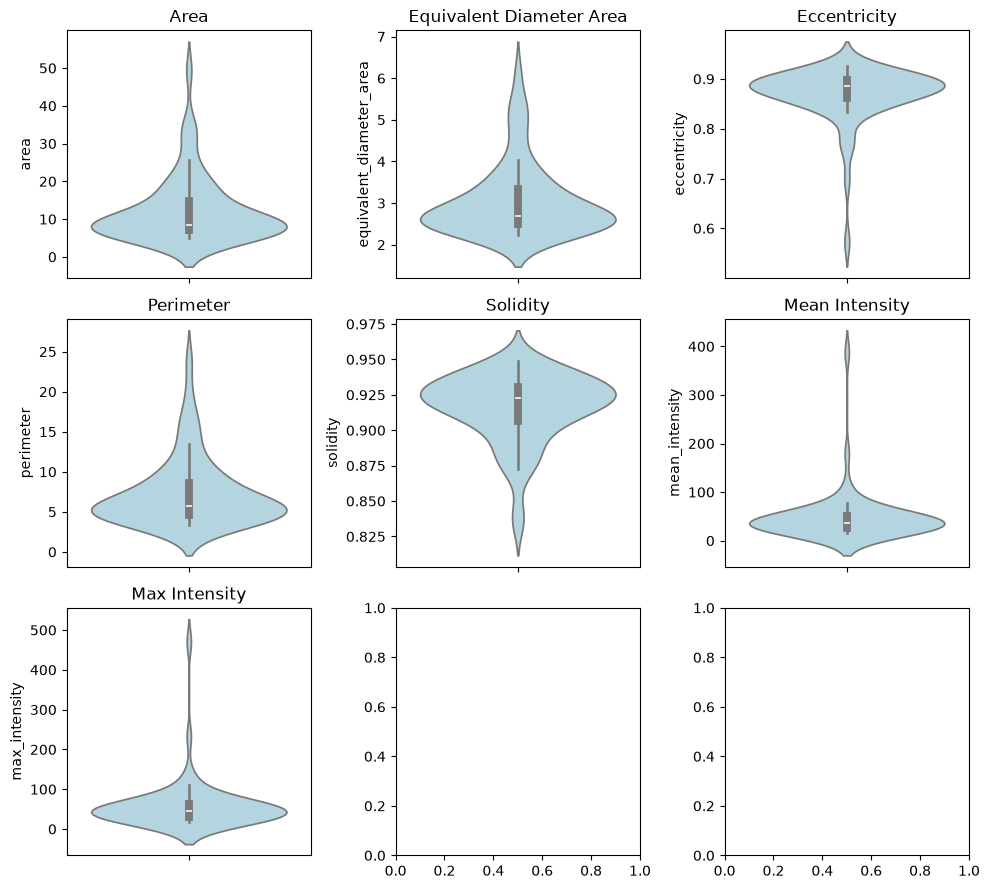

In [12]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [21]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

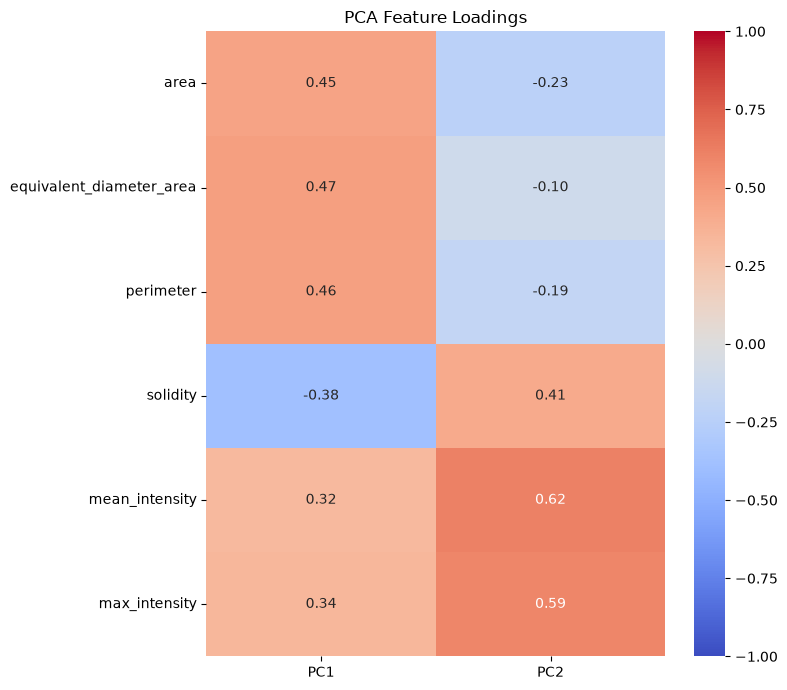

In [22]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [23]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS3    0.679575  0.206783
WT     -0.465994 -0.141794


In [32]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

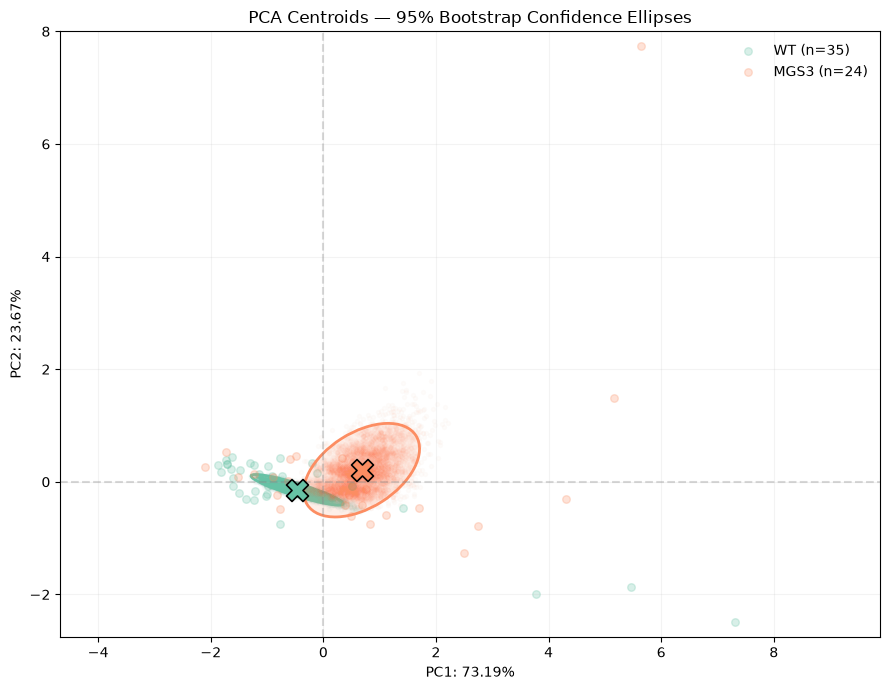

In [27]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95
)

In [ ]:
results_df = pca_permanova(
    pca_df,
    group_col="sample"
)

results_df

        Test  Statistic  p_value        R2   n  groups
0  PERMANOVA   3.608484   0.0346  0.059538  59       2
1   PERMDISP   1.627468   0.2120       NaN  59       2
